In [5]:
import pandas as pd

df = pd.read_csv("hospital_final.csv.csv")
print(df.shape)
df.head()

(4790, 15)


,facility_id,facility_name,state,hospital_type,hospital_ownership,ownership_group,patient_survey_star_rating,hai_1_sir,hai_2_sir,hai_3_sir,hai_4_sir,hai_5_sir,hai_6_sir,psi_90_score,psi_90_label
0,05020F,NH Camp Pendleton,CA,Acute Care - Department of Defense,Department of Defense,Government,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,45069F,Brooke Army Medical Center (FT Sam Houston),TX,Acute Care - Department of Defense,Department of Defense,Government,5.0,0.442,0.224,NaN,NaN,NaN,0.987,NaN,NaN
2,05039F,NH Twentynine Palms,CA,Acute Care - Department of Defense,Department of Defense,Government,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,21007F,Walter Reed National Military Med Cen,MD,Acute Care - Department of Defense,Department of Defense,Government,4.0,0.248,0.000,NaN,NaN,NaN,0.408,NaN,NaN
4,34014F,Womack AMC (FT Bragg),NC,Acute Care - Department of Defense,Department of Defense,Government,5.0,NaN,NaN,NaN,NaN,NaN,0.623,NaN,NaN


In [7]:
df_model = df.dropna(subset=["patient_survey_star_rating", "psi_90_score"]).copy()
print(df_model.shape)
print(df_model[["patient_survey_star_rating", "psi_90_score"]].describe())

(2754, 15)
       patient_survey_star_rating  psi_90_score
count                 2754.000000   2754.000000
mean                     3.129267      0.997658
std                      0.830315      0.198845
min                      1.000000      0.400000
25%                      3.000000      0.890000
50%                      3.000000      0.960000
75%                      4.000000      1.060000
max                      5.000000      3.160000


In [9]:
!pip install statsmodels

In [10]:
#Multiple Linear Regression
import statsmodels.formula.api as smf

model = smf.ols(
    "psi_90_score ~ patient_survey_star_rating + C(ownership_group) + C(hospital_type) + C(state)",
    data=df_model
).fit()

print(model.params["patient_survey_star_rating"]) #difference bewtween star rating and effect also called coefficient
print(model.pvalues["patient_survey_star_rating"]) #pvalue-shuffled 10000 times
print(model.conf_int().loc["patient_survey_star_rating"]) #The range for the true star effect
print(model.nobs, model.rsquared) #hospitals used and rsquare

-0.027336286498408614
6.03631218200802e-08
0   -0.037202
1   -0.017470
Name: patient_survey_star_rating, dtype: float64
2754.0 0.08166866708496023


NameError: name 'plt' is not defined

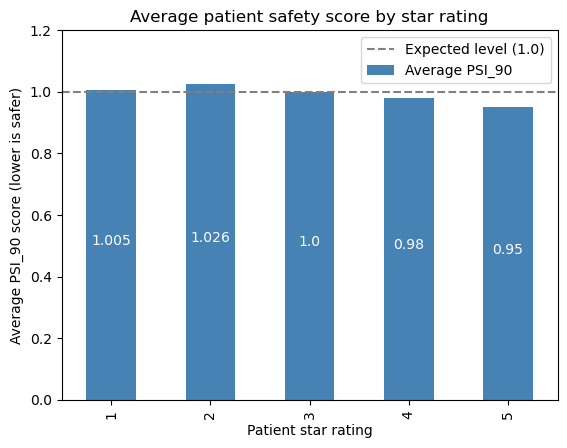

In [11]:
avg = df_model.groupby("patient_survey_star_rating")["psi_90_score"].mean().round(3)
avg.index = avg.index.astype(int)

ax = avg.plot(kind="bar", color="steelblue", label="Average PSI_90")
ax.axhline(1.0, color="gray", linestyle="--", label="Expected level (1.0)")
for i, v in enumerate(avg):
    ax.text(i, v / 2, str(v), ha="center", color="white")
ax.set_xlabel("Patient star rating")
ax.set_ylabel("Average PSI_90 score (lower is safer)")
ax.set_title("Average patient safety score by star rating")
ax.set_ylim(0, 1.2)
ax.legend()
plt.xticks(rotation=0)
plt.show()

In [17]:
import numpy as np

df_model["worse"] = (df_model["psi_90_label"] == "Worse").astype(int)

logit = smf.logit(
    "worse ~ patient_survey_star_rating + C(ownership_group) + C(hospital_type)",
    data=df_model
).fit()

coef = logit.params["patient_survey_star_rating"]
print(round(np.exp(coef), 3))
print(logit.pvalues["patient_survey_star_rating"])
print(np.exp(logit.conf_int().loc["patient_survey_star_rating"]))
print(df_model["worse"].sum(), logit.nobs)

Optimization terminated successfully.
         Current function value: 0.211758
         Iterations 8
0.568
1.8561647572788494e-07
0    0.459713
1    0.702956
Name: patient_survey_star_rating, dtype: float64
159 2754


In [16]:
!pip install scikit-learn

In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

features = ["patient_survey_star_rating", "ownership_group", "hospital_type", "state"]
X = df_model[features]
y = df_model["psi_90_score"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pre = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), ["ownership_group", "hospital_type", "state"])],
    remainder="passthrough"
)
rf = Pipeline([
    ("pre", pre),
    ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=10, random_state=42))
])
rf.fit(X_train, y_train)
print("Test R squared:", round(rf.score(X_test, y_test), 3))

imp = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=42)
print(pd.Series(imp.importances_mean, index=features).sort_values(ascending=False).round(4))

Test R squared: 0.041
state                         0.0471
ownership_group               0.0372
patient_survey_star_rating    0.0223
hospital_type                 0.0083
dtype: float64


In [18]:
specs = [
    ("1. No controls", "psi_90_score ~ patient_survey_star_rating"),
    ("2. + ownership", "psi_90_score ~ patient_survey_star_rating + C(ownership_group)"),
    ("3. + ownership + type", "psi_90_score ~ patient_survey_star_rating + C(ownership_group) + C(hospital_type)"),
    ("4. + ownership + type + state", "psi_90_score ~ patient_survey_star_rating + C(ownership_group) + C(hospital_type) + C(state)"),
]

for name, formula in specs:
    m = smf.ols(formula, data=df_model).fit()
    print(name, round(m.params["patient_survey_star_rating"], 4))

1. No controls -0.0204
2. + ownership -0.0265
3. + ownership + type -0.028
4. + ownership + type + state -0.0273


In [21]:
import numpy as np

x = df_model["patient_survey_star_rating"].values
y = df_model["psi_90_score"].values

real_step = np.polyfit(x, y, 1)[0]

rng = np.random.default_rng(42)
fake_steps = np.array([np.polyfit(rng.permutation(x), y, 1)[0] for _ in range(10000)])

print("Real step:", round(real_step, 4))
print("Biggest negative step from shuffling:", round(fake_steps.min(), 4))
print("Shuffles as extreme as the real step:", (fake_steps <= real_step).sum(), "out of 10000")

Real step: -0.0204
Biggest negative step from shuffling: -0.0161
Shuffles as extreme as the real step: 0 out of 10000
